In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("/content/penguins.csv")
df

,id,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
...,...,...,...,...,...,...,...,...,...
339,339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 344 non-null    int64  
 1   species            344 non-null    object 
 2   island             344 non-null    object 
 3   bill_length_mm     342 non-null    float64
 4   bill_depth_mm      342 non-null    float64
 5   flipper_length_mm  342 non-null    float64
 6   body_mass_g        342 non-null    float64
 7   sex                333 non-null    object 
 8   year               344 non-null    int64  
dtypes: float64(4), int64(2), object(3)
memory usage: 24.3+ KB


In [5]:
df.shape

(344, 9)

In [6]:
df.dtypes

,0
id,int64
species,object
island,object
bill_length_mm,float64
bill_depth_mm,float64
flipper_length_mm,float64
body_mass_g,float64
sex,object
year,int64


In [7]:
df.memory_usage(deep=True)

,0
Index,132
id,2752
species,19124
island,18952
bill_length_mm,2752
bill_depth_mm,2752
flipper_length_mm,2752
body_mass_g,2752
sex,18331
year,2752


In [8]:
df["species"].describe()

,species
count,344
unique,3
top,Adelie
freq,152


In [9]:
df["species"].isnull().sum()/len(df["species"])

np.float64(0.0)

In [10]:
df["island"].describe()

,island
count,344
unique,3
top,Biscoe
freq,168


In [11]:
df["island"].isnull().sum()/len(df["island"])

np.float64(0.0)

In [12]:
df["sex"].describe()

,sex
count,333
unique,2
top,male
freq,168


In [13]:
df["sex"].isnull().sum()/len(df["sex"])

np.float64(0.03197674418604651)

In [14]:
print(df["sex"].isnull().sum())

11


In [15]:
df["bill_length_mm"].describe()

,bill_length_mm
count,342.000000
mean,43.921930
std,5.459584
min,32.100000
25%,39.225000
50%,44.450000
75%,48.500000
max,59.600000


In [16]:
df["bill_length_mm"].isnull().sum()/len(df["bill_length_mm"])

np.float64(0.005813953488372093)

In [17]:
print(df["bill_length_mm"].isnull().sum())

2


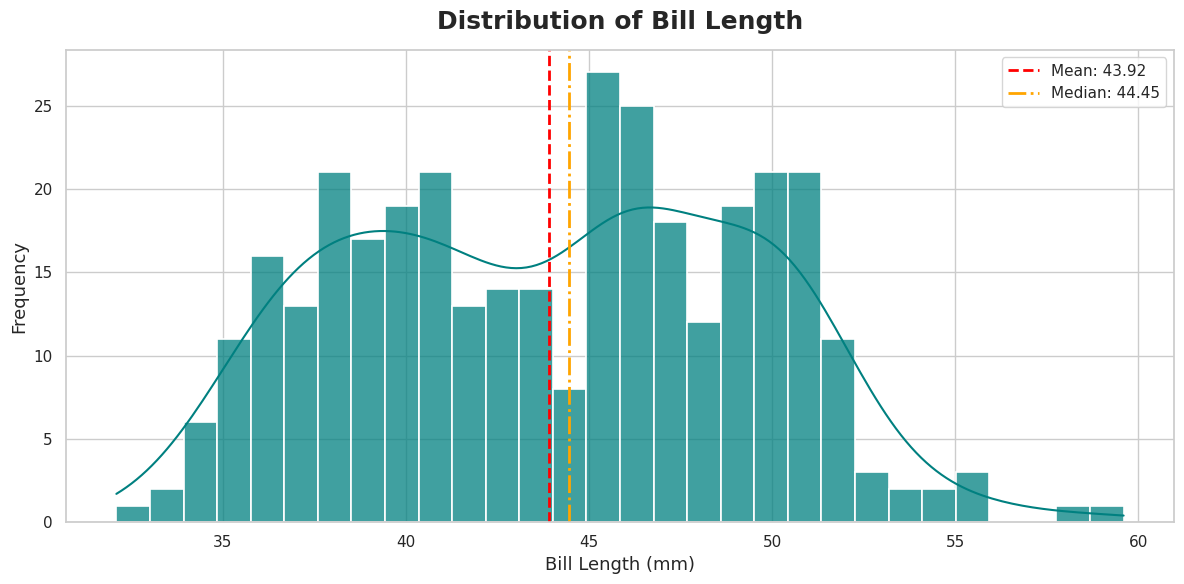

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="bill_length_mm",
    bins=30,
    kde=True,
    color="teal",
    edgecolor="white",
    linewidth=1.2,
    alpha=0.75,
    stat="count"
)

# Mean and median
mean_val = df["bill_length_mm"].mean()
median_val = df["bill_length_mm"].median()

plt.axvline(
    mean_val,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_val:.2f}"
)

plt.axvline(
    median_val,
    color="orange",
    linestyle="-.",
    linewidth=2,
    label=f"Median: {median_val:.2f}"
)

plt.title("Distribution of Bill Length", fontsize=18, fontweight="bold", pad=15)
plt.xlabel("Bill Length (mm)", fontsize=13)
plt.ylabel("Frequency", fontsize=13)

plt.legend(frameon=True, fontsize=11)
plt.tight_layout()
plt.show()

In [19]:
df["bill_length_mm"].skew()

np.float64(0.05311806699132413)

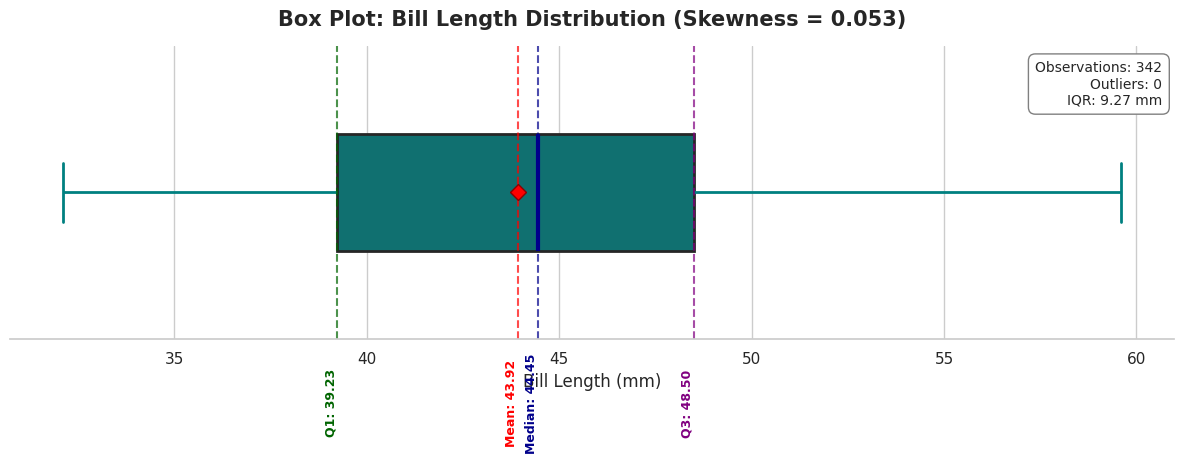

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

col = "bill_length_mm"
data = df[col].dropna()

# Calculate statistics
Q1 = data.quantile(0.25)
Q2 = data.median()
Q3 = data.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = data[(data < lower_bound) | (data > upper_bound)]

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(12, 5))

sns.boxplot(
    x=data,
    color="teal",
    width=0.4,
    linewidth=2,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "red",
        "markeredgecolor": "darkred",
        "markersize": 8
    },
    medianprops={"color": "darkblue", "linewidth": 3},
    whiskerprops={"color": "teal", "linewidth": 2},
    capprops={"color": "teal", "linewidth": 2},
    flierprops={
        "marker": "o",
        "markerfacecolor": "orange",
        "markeredgecolor": "darkred",
        "markersize": 7,
        "alpha": 0.8
    },
    ax=ax
)

# Annotate key statistics
for value, label, color in [
    (Q1, f"Q1: {Q1:.2f}", "darkgreen"),
    (Q2, f"Median: {Q2:.2f}", "darkblue"),
    (Q3, f"Q3: {Q3:.2f}", "purple"),
    (data.mean(), f"Mean: {data.mean():.2f}", "red")
]:
    ax.axvline(value, color=color, linestyle="--", alpha=0.7)
    ax.text(
        value, 0.72, label,
        rotation=90, color=color,
        ha="right", va="center",
        fontsize=9, fontweight="bold"
    )

ax.set_title(
    f"Box Plot: Bill Length Distribution (Skewness = {data.skew():.3f})",
    fontsize=15, fontweight="bold", pad=15
)
ax.set_xlabel("Bill Length (mm)", fontsize=12)
ax.set_yticks([])
ax.set_ylabel("")

ax.text(
    0.99, 0.95,
    f"Observations: {len(data)}\nOutliers: {len(outliers)}\nIQR: {IQR:.2f} mm",
    transform=ax.transAxes,
    ha="right", va="top",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="gray"),
    fontsize=10
)

sns.despine(left=True)
plt.tight_layout()
plt.show()

In [21]:
df["bill_depth_mm"].describe()

,bill_depth_mm
count,342.000000
mean,17.151170
std,1.974793
min,13.100000
25%,15.600000
50%,17.300000
75%,18.700000
max,21.500000


In [22]:
df["bill_depth_mm"].isnull().sum()/len(df["bill_depth_mm"])

np.float64(0.005813953488372093)

In [23]:
print(df["bill_depth_mm"].isnull().sum())

2


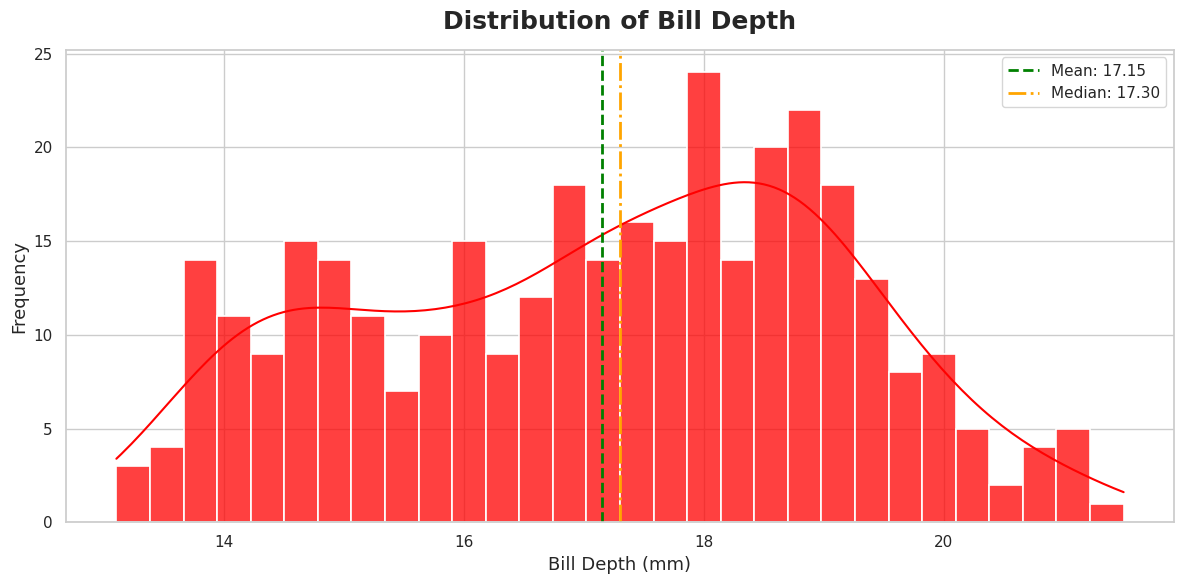

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="bill_depth_mm",
    bins=30,
    kde=True,
    color="red",
    edgecolor="white",
    linewidth=1.2,
    alpha=0.75,
    stat="count"
)

# Mean and median
mean_val = df["bill_depth_mm"].mean()
median_val = df["bill_depth_mm"].median()

plt.axvline(
    mean_val,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_val:.2f}"
)

plt.axvline(
    median_val,
    color="orange",
    linestyle="-.",
    linewidth=2,
    label=f"Median: {median_val:.2f}"
)

plt.title("Distribution of Bill Depth", fontsize=18, fontweight="bold", pad=15)
plt.xlabel("Bill Depth (mm)", fontsize=13)
plt.ylabel("Frequency", fontsize=13)

plt.legend(frameon=True, fontsize=11)
plt.tight_layout()
plt.show()

In [25]:
df["bill_depth_mm"].skew()

np.float64(-0.14346462519436454)

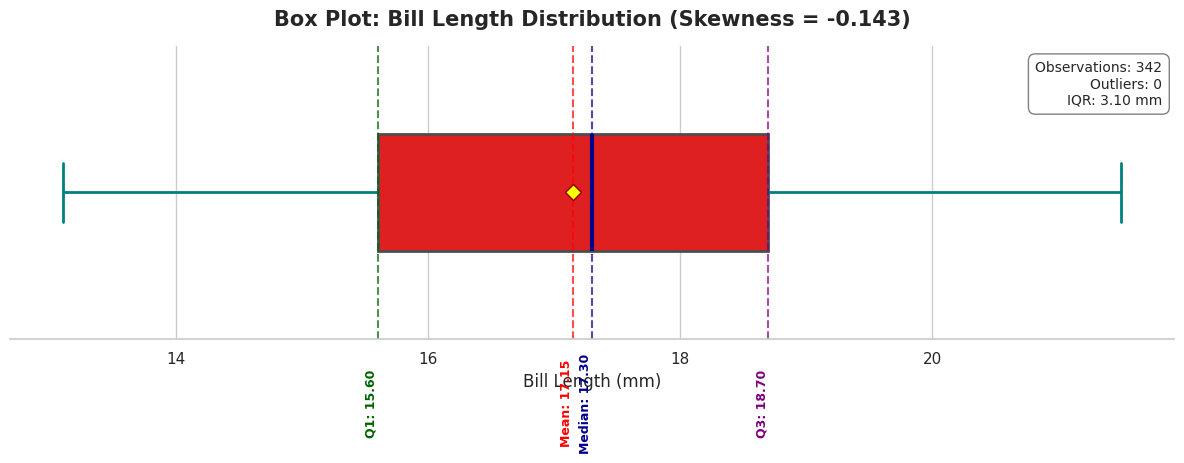

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

col = "bill_depth_mm"
data = df[col].dropna()

# Calculate statistics
Q1 = data.quantile(0.25)
Q2 = data.median()
Q3 = data.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = data[(data < lower_bound) | (data > upper_bound)]

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(12, 5))

sns.boxplot(
    x=data,
    color="red",
    width=0.4,
    linewidth=2,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "yellow",
        "markeredgecolor": "darkred",
        "markersize": 8
    },
    medianprops={"color": "darkblue", "linewidth": 3},
    whiskerprops={"color": "teal", "linewidth": 2},
    capprops={"color": "teal", "linewidth": 2},
    flierprops={
        "marker": "o",
        "markerfacecolor": "yellow",
        "markeredgecolor": "darkred",
        "markersize": 7,
        "alpha": 0.8
    },
    ax=ax
)

# Annotate key statistics
for value, label, color in [
    (Q1, f"Q1: {Q1:.2f}", "darkgreen"),
    (Q2, f"Median: {Q2:.2f}", "darkblue"),
    (Q3, f"Q3: {Q3:.2f}", "purple"),
    (data.mean(), f"Mean: {data.mean():.2f}", "red")
]:
    ax.axvline(value, color=color, linestyle="--", alpha=0.7)
    ax.text(
        value, 0.72, label,
        rotation=90, color=color,
        ha="right", va="center",
        fontsize=9, fontweight="bold"
    )

ax.set_title(
    f"Box Plot: Bill Length Distribution (Skewness = {data.skew():.3f})",
    fontsize=15, fontweight="bold", pad=15
)
ax.set_xlabel("Bill Length (mm)", fontsize=12)
ax.set_yticks([])
ax.set_ylabel("")

ax.text(
    0.99, 0.95,
    f"Observations: {len(data)}\nOutliers: {len(outliers)}\nIQR: {IQR:.2f} mm",
    transform=ax.transAxes,
    ha="right", va="top",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="gray"),
    fontsize=10
)

sns.despine(left=True)
plt.tight_layout()
plt.show()

In [27]:
df["flipper_length_mm"].describe()

,flipper_length_mm
count,342.000000
mean,200.915205
std,14.061714
min,172.000000
25%,190.000000
50%,197.000000
75%,213.000000
max,231.000000


In [28]:
df["flipper_length_mm"].isnull().sum()/len(df["flipper_length_mm"])

np.float64(0.005813953488372093)

In [29]:
print(df["flipper_length_mm"].isnull().sum())

2


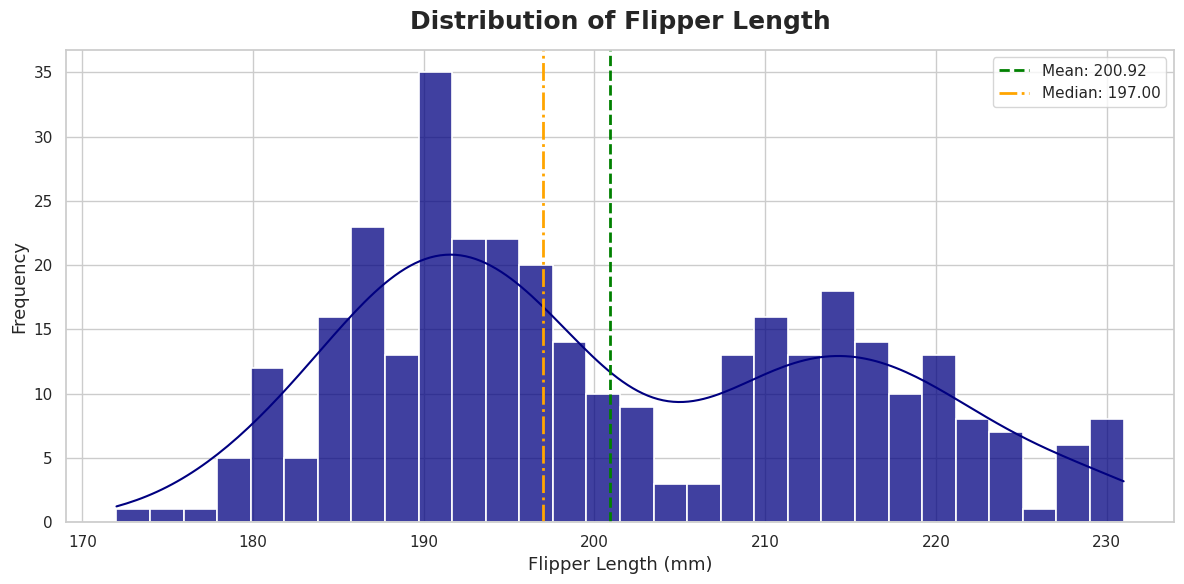

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="flipper_length_mm",
    bins=30,
    kde=True,
    color="navy",
    edgecolor="white",
    linewidth=1.2,
    alpha=0.75,
    stat="count"
)

# Mean and median
mean_val = df["flipper_length_mm"].mean()
median_val = df["flipper_length_mm"].median()

plt.axvline(
    mean_val,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_val:.2f}"
)

plt.axvline(
    median_val,
    color="orange",
    linestyle="-.",
    linewidth=2,
    label=f"Median: {median_val:.2f}"
)

plt.title("Distribution of Flipper Length", fontsize=18, fontweight="bold", pad=15)
plt.xlabel("Flipper Length (mm)", fontsize=13)
plt.ylabel("Frequency", fontsize=13)

plt.legend(frameon=True, fontsize=11)
plt.tight_layout()
plt.show()

In [31]:
df["flipper_length_mm"].skew()

np.float64(0.3456818328687695)

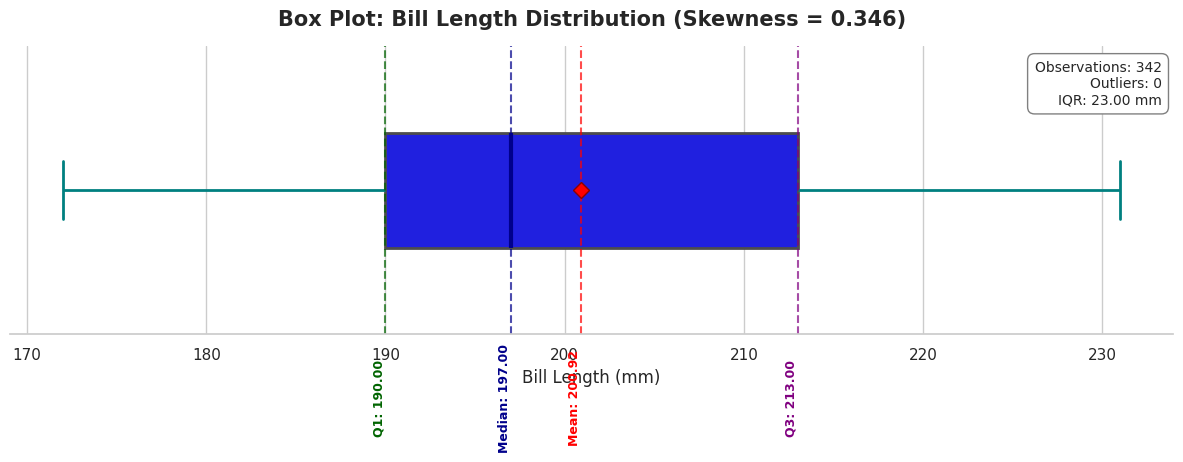

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

col = "flipper_length_mm"
data = df[col].dropna()

# Calculate statistics
Q1 = data.quantile(0.25)
Q2 = data.median()
Q3 = data.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = data[(data < lower_bound) | (data > upper_bound)]

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(12, 5))

sns.boxplot(
    x=data,
    color="blue",
    width=0.4,
    linewidth=2,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "red",
        "markeredgecolor": "darkred",
        "markersize": 8
    },
    medianprops={"color": "darkblue", "linewidth": 3},
    whiskerprops={"color": "teal", "linewidth": 2},
    capprops={"color": "teal", "linewidth": 2},
    flierprops={
        "marker": "o",
        "markerfacecolor": "orange",
        "markeredgecolor": "darkred",
        "markersize": 7,
        "alpha": 0.8
    },
    ax=ax
)

# Annotate key statistics
for value, label, color in [
    (Q1, f"Q1: {Q1:.2f}", "darkgreen"),
    (Q2, f"Median: {Q2:.2f}", "darkblue"),
    (Q3, f"Q3: {Q3:.2f}", "purple"),
    (data.mean(), f"Mean: {data.mean():.2f}", "red")
]:
    ax.axvline(value, color=color, linestyle="--", alpha=0.7)
    ax.text(
        value, 0.72, label,
        rotation=90, color=color,
        ha="right", va="center",
        fontsize=9, fontweight="bold"
    )

ax.set_title(
    f"Box Plot: Bill Length Distribution (Skewness = {data.skew():.3f})",
    fontsize=15, fontweight="bold", pad=15
)
ax.set_xlabel("Bill Length (mm)", fontsize=12)
ax.set_yticks([])
ax.set_ylabel("")

ax.text(
    0.99, 0.95,
    f"Observations: {len(data)}\nOutliers: {len(outliers)}\nIQR: {IQR:.2f} mm",
    transform=ax.transAxes,
    ha="right", va="top",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="gray"),
    fontsize=10
)

sns.despine(left=True)
plt.tight_layout()
plt.show()

In [33]:
df["body_mass_g"].describe()

,body_mass_g
count,342.000000
mean,4201.754386
std,801.954536
min,2700.000000
25%,3550.000000
50%,4050.000000
75%,4750.000000
max,6300.000000


In [34]:
df["body_mass_g"].isnull().sum()/len(df["body_mass_g"])

np.float64(0.005813953488372093)

In [35]:
print(df["body_mass_g"].isnull().sum())

2


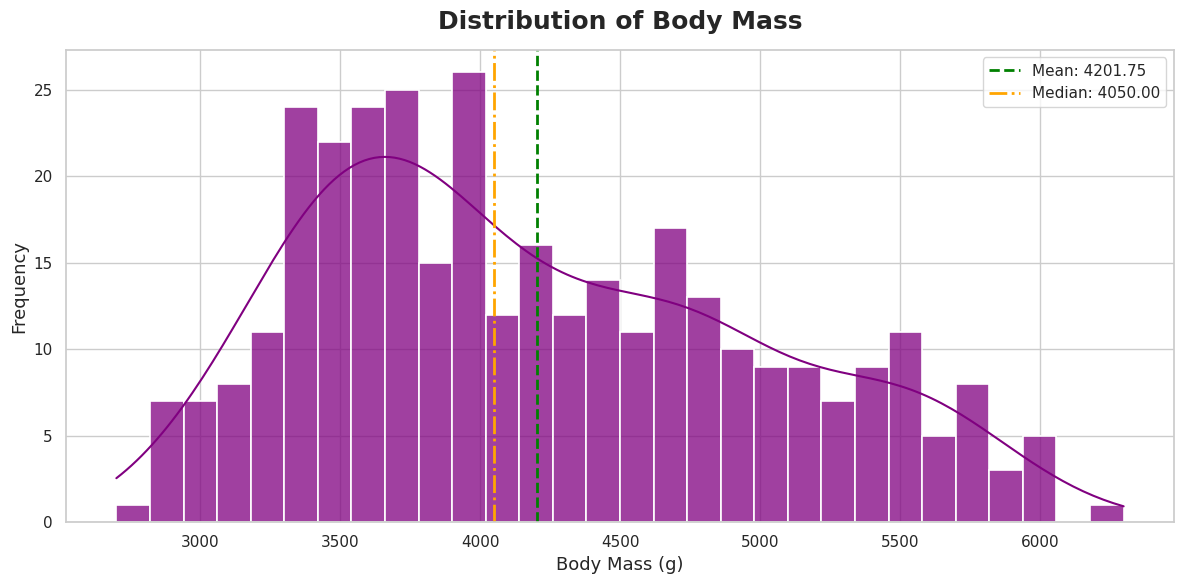

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="body_mass_g",
    bins=30,
    kde=True,
    color="purple",
    edgecolor="white",
    linewidth=1.2,
    alpha=0.75,
    stat="count"
)

# Mean and median
mean_val = df["body_mass_g"].mean()
median_val = df["body_mass_g"].median()

plt.axvline(
    mean_val,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_val:.2f}"
)

plt.axvline(
    median_val,
    color="orange",
    linestyle="-.",
    linewidth=2,
    label=f"Median: {median_val:.2f}"
)

plt.title("Distribution of Body Mass", fontsize=18, fontweight="bold", pad=15)
plt.xlabel("Body Mass (g)", fontsize=13)
plt.ylabel("Frequency", fontsize=13)

plt.legend(frameon=True, fontsize=11)
plt.tight_layout()
plt.show()

In [37]:
df["body_mass_g"].skew()

np.float64(0.4703293304801231)

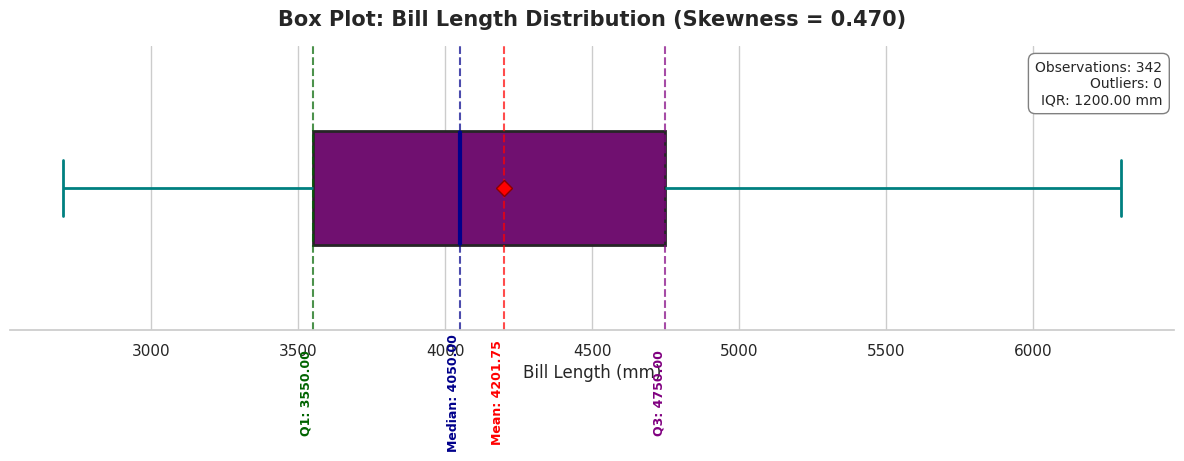

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

col = "body_mass_g"
data = df[col].dropna()

# Calculate statistics
Q1 = data.quantile(0.25)
Q2 = data.median()
Q3 = data.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = data[(data < lower_bound) | (data > upper_bound)]

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(12, 5))

sns.boxplot(
    x=data,
    color="purple",
    width=0.4,
    linewidth=2,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "red",
        "markeredgecolor": "darkred",
        "markersize": 8
    },
    medianprops={"color": "darkblue", "linewidth": 3},
    whiskerprops={"color": "teal", "linewidth": 2},
    capprops={"color": "teal", "linewidth": 2},
    flierprops={
        "marker": "o",
        "markerfacecolor": "orange",
        "markeredgecolor": "darkred",
        "markersize": 7,
        "alpha": 0.8
    },
    ax=ax
)

# Annotate key statistics
for value, label, color in [
    (Q1, f"Q1: {Q1:.2f}", "darkgreen"),
    (Q2, f"Median: {Q2:.2f}", "darkblue"),
    (Q3, f"Q3: {Q3:.2f}", "purple"),
    (data.mean(), f"Mean: {data.mean():.2f}", "red")
]:
    ax.axvline(value, color=color, linestyle="--", alpha=0.7)
    ax.text(
        value, 0.72, label,
        rotation=90, color=color,
        ha="right", va="center",
        fontsize=9, fontweight="bold"
    )

ax.set_title(
    f"Box Plot: Bill Length Distribution (Skewness = {data.skew():.3f})",
    fontsize=15, fontweight="bold", pad=15
)
ax.set_xlabel("Bill Length (mm)", fontsize=12)
ax.set_yticks([])
ax.set_ylabel("")

ax.text(
    0.99, 0.95,
    f"Observations: {len(data)}\nOutliers: {len(outliers)}\nIQR: {IQR:.2f} mm",
    transform=ax.transAxes,
    ha="right", va="top",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="gray"),
    fontsize=10
)

sns.despine(left=True)
plt.tight_layout()
plt.show()

In [39]:
pd.crosstab(df["species"], df["island"], normalize = "columns") * 100

island,Biscoe,Dream,Torgersen
species,,,
Adelie,26.190476,45.16129,100.0
Chinstrap,0.000000,54.83871,0.0
Gentoo,73.809524,0.00000,0.0


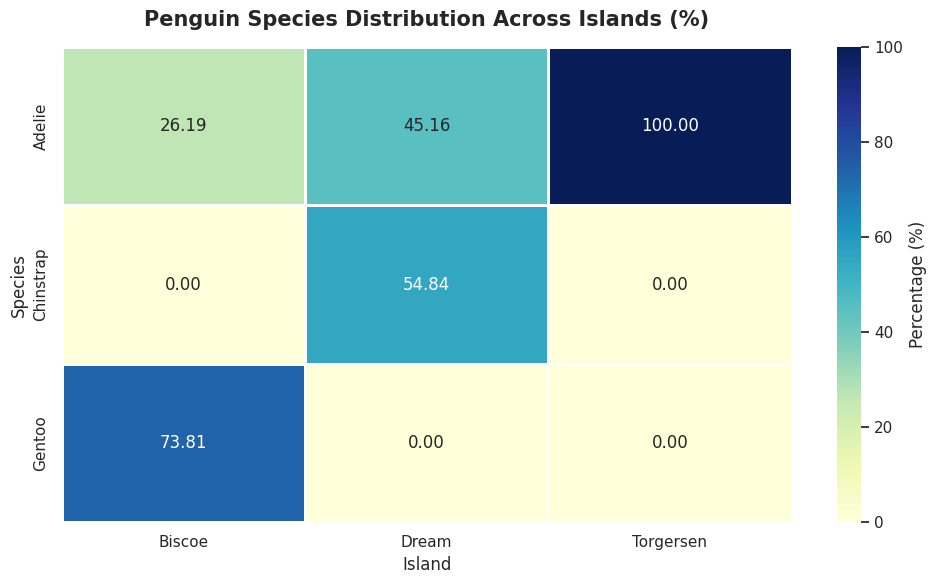

In [40]:
ct = pd.crosstab(df["species"], df["island"], normalize="columns") * 100
plt.figure(figsize=(10, 6))
sns.heatmap(ct, annot=True, fmt=".2f", cmap="YlGnBu", linewidths=1, linecolor="white", cbar_kws={"label": "Percentage (%)"}, vmin=0, vmax=100)
plt.title("Penguin Species Distribution Across Islands (%)", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Island", fontsize=12)
plt.ylabel("Species", fontsize=12)
plt.tight_layout()
plt.show()

In [41]:
pd.crosstab(df["species"], df["sex"], normalize = "columns") * 100

sex,female,male
species,,
Adelie,44.242424,43.452381
Chinstrap,20.606061,20.238095
Gentoo,35.151515,36.309524


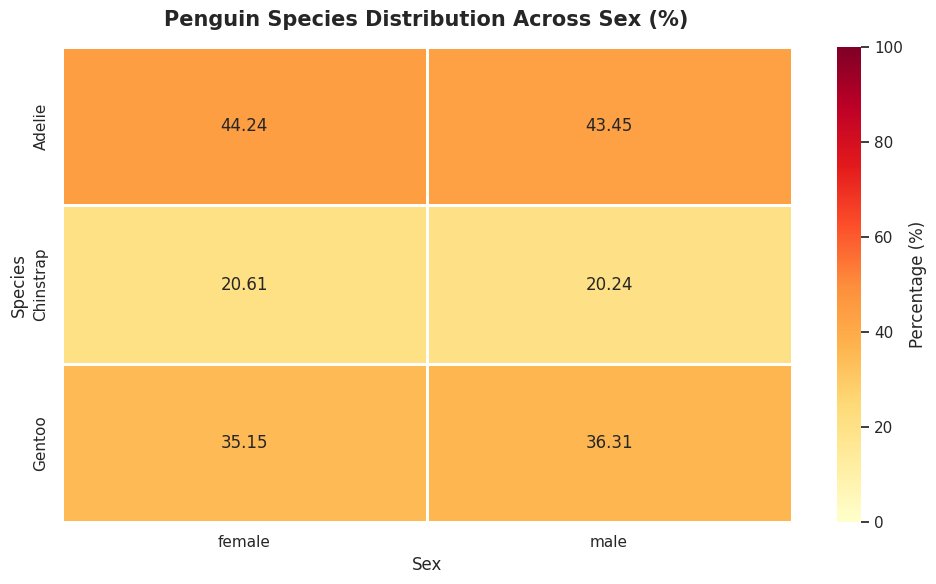

In [42]:
ct = pd.crosstab(df["species"], df["sex"], normalize="columns") * 100
plt.figure(figsize=(10, 6))
sns.heatmap(ct, annot=True, fmt=".2f", cmap="YlOrRd", linewidths=1, linecolor="white", cbar_kws={"label": "Percentage (%)"}, vmin=0, vmax=100)
plt.title("Penguin Species Distribution Across Sex (%)", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Sex", fontsize=12)
plt.ylabel("Species", fontsize=12)
plt.tight_layout()
plt.show()

In [43]:
pd.crosstab(df["sex"], df["island"], normalize = "columns") * 100

island,Biscoe,Dream,Torgersen
sex,,,
female,49.079755,49.593496,51.06383
male,50.920245,50.406504,48.93617


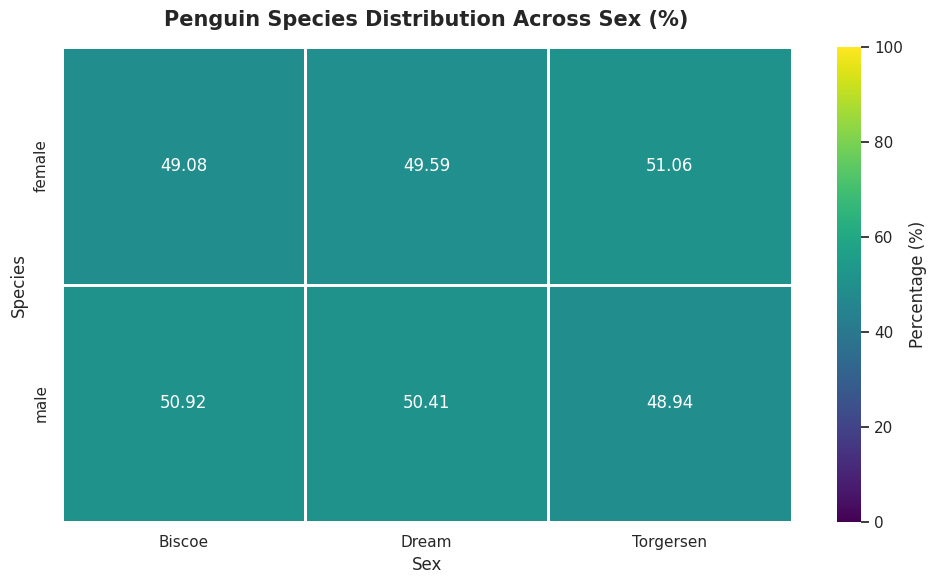

In [44]:
ct = pd.crosstab(df["sex"], df["island"], normalize="columns") * 100
plt.figure(figsize=(10, 6))
sns.heatmap(ct, annot=True, fmt=".2f", cmap="viridis", linewidths=1, linecolor="white", cbar_kws={"label": "Percentage (%)"}, vmin=0, vmax=100)
plt.title("Penguin Species Distribution Across Sex (%)", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Sex", fontsize=12)
plt.ylabel("Species", fontsize=12)
plt.tight_layout()
plt.show()

In [45]:
pd.crosstab(df["species"], df["year"], normalize = "columns") * 100

year,2007,2008,2009
species,,,
Adelie,45.454545,43.859649,43.333333
Chinstrap,23.636364,15.789474,20.000000
Gentoo,30.909091,40.350877,36.666667


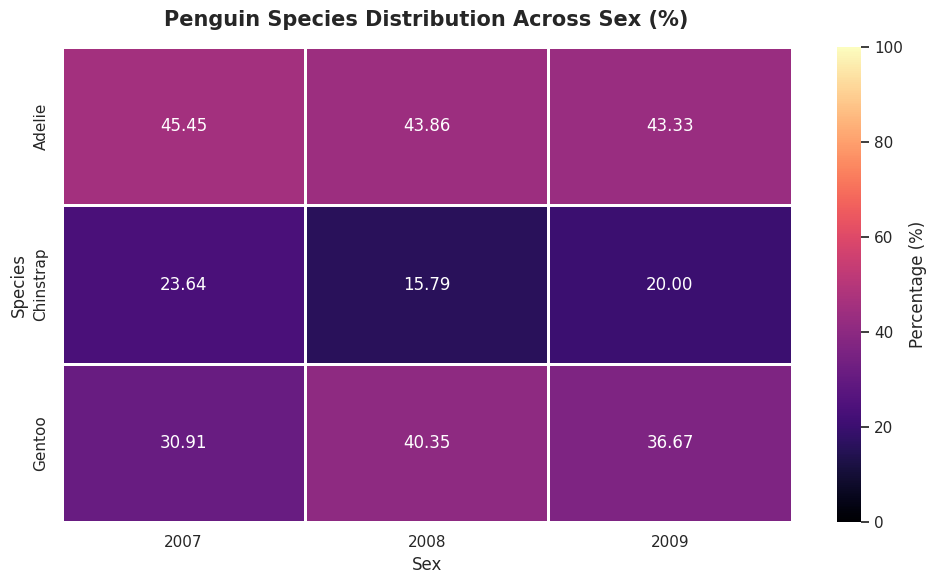

In [46]:
ct = pd.crosstab(df["species"], df["year"], normalize="columns") * 100
plt.figure(figsize=(10, 6))
sns.heatmap(ct, annot=True, fmt=".2f", cmap="magma", linewidths=1, linecolor="white", cbar_kws={"label": "Percentage (%)"}, vmin=0, vmax=100)
plt.title("Penguin Species Distribution Across Sex (%)", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Sex", fontsize=12)
plt.ylabel("Species", fontsize=12)
plt.tight_layout()
plt.show()

In [47]:
pd.crosstab(df["sex"], df["year"], normalize = "columns") * 100

year,2007,2008,2009
sex,,,
female,49.514563,49.557522,49.57265
male,50.485437,50.442478,50.42735


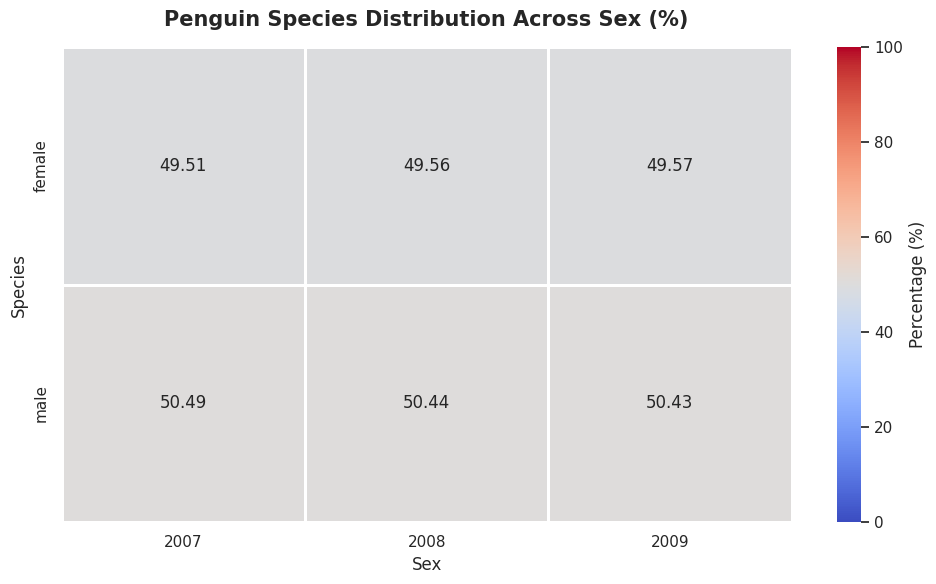

In [48]:
ct = pd.crosstab(df["sex"], df["year"], normalize="columns") * 100
plt.figure(figsize=(10, 6))
sns.heatmap(ct, annot=True, fmt=".2f", cmap="coolwarm", linewidths=1, linecolor="white", cbar_kws={"label": "Percentage (%)"}, vmin=0, vmax=100)
plt.title("Penguin Species Distribution Across Sex (%)", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Sex", fontsize=12)
plt.ylabel("Species", fontsize=12)
plt.tight_layout()
plt.show()

In [49]:
pd.crosstab(df["year"], df["island"], normalize = "columns") * 100

island,Biscoe,Dream,Torgersen
year,,,
2007,26.190476,37.096774,38.461538
2008,38.095238,27.419355,30.769231
2009,35.714286,35.483871,30.769231


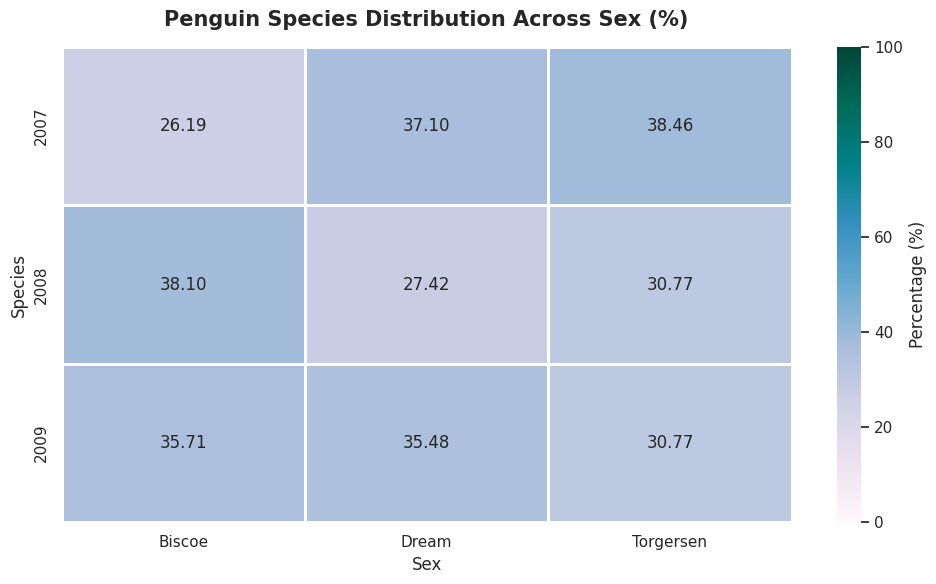

In [50]:
ct = pd.crosstab(df["year"], df["island"], normalize="columns") * 100
plt.figure(figsize=(10, 6))
sns.heatmap(ct, annot=True, fmt=".2f", cmap="PuBuGn", linewidths=1, linecolor="white", cbar_kws={"label": "Percentage (%)"}, vmin=0, vmax=100)
plt.title("Penguin Species Distribution Across Sex (%)", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Sex", fontsize=12)
plt.ylabel("Species", fontsize=12)
plt.tight_layout()
plt.show()

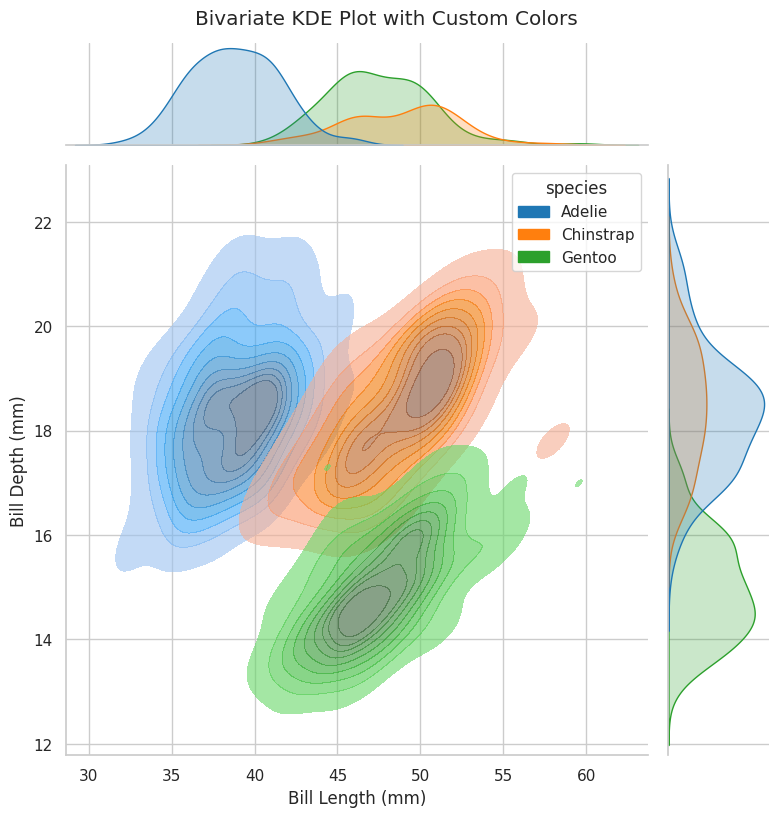

In [64]:
custom_palette = ["#1f77b4", "#ff7f0e", "#2ca02c"]
g = sns.jointplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="species", kind="kde", fill=True, common_norm=False, alpha=0.6, height=8, palette=custom_palette)
g.set_axis_labels("Bill Length (mm)", "Bill Depth (mm)")
g.fig.suptitle("Bivariate KDE Plot with Custom Colors", y=1.02)
plt.show()

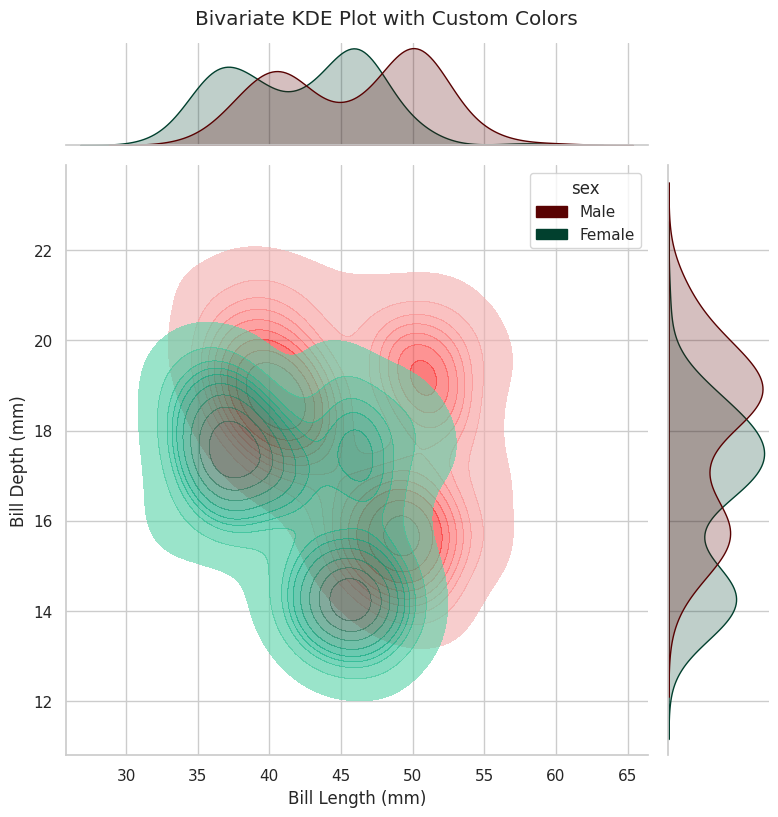

In [79]:
custom_palette = ["#590202", "#01402e"]
g = sns.jointplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="sex", kind="kde", fill=True, common_norm=False, alpha=0.6, height=8, palette=custom_palette)
g.set_axis_labels("Bill Length (mm)", "Bill Depth (mm)")
g.fig.suptitle("Bivariate KDE Plot with Custom Colors", y=1.02)
plt.show()

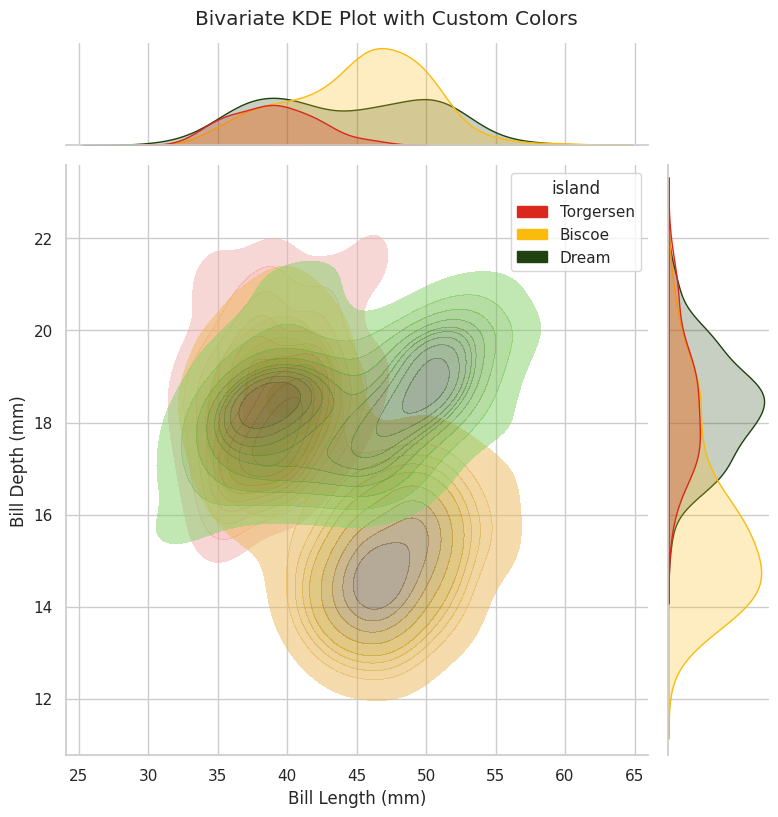

In [68]:
custom_palette = ["#db281c", "#fbbb0b", "#204110"]
g = sns.jointplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="island", kind="kde", fill=True, common_norm=False, alpha=0.5, height=8, palette=custom_palette)
g.set_axis_labels("Bill Length (mm)", "Bill Depth (mm)")
g.fig.suptitle("Bivariate KDE Plot with Custom Colors", y=1.02)
plt.show()

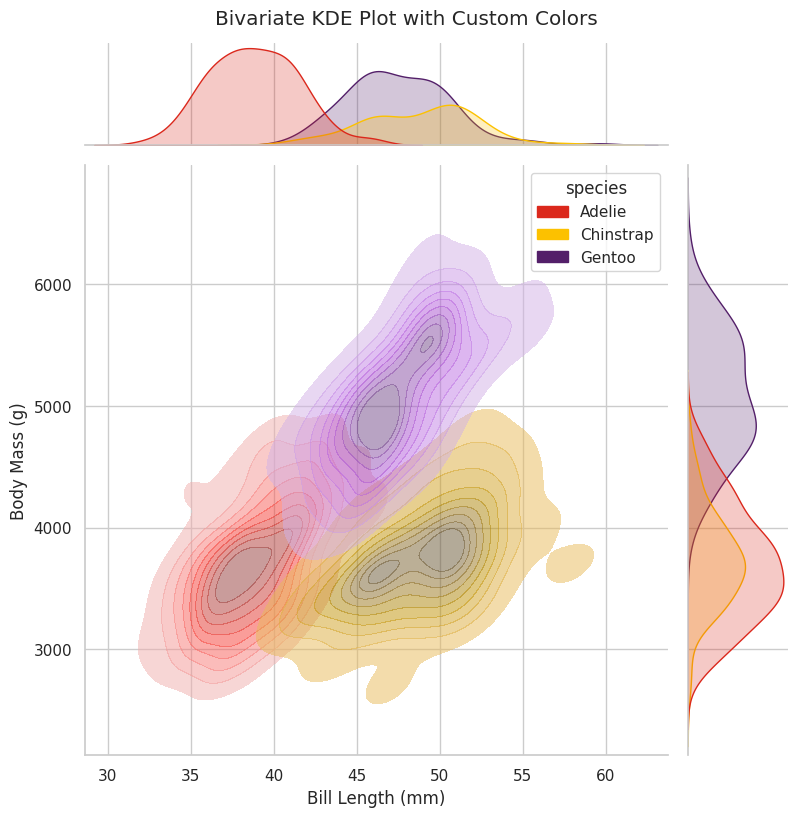

In [73]:
custom_palette = ["#db281c", "#fcc100", "#531f69"]
g = sns.jointplot(data=df, x="bill_length_mm", y="body_mass_g", hue="species", kind="kde", fill=True, common_norm=False, alpha=0.5, height=8, palette=custom_palette)
g.set_axis_labels("Bill Length (mm)", "Body Mass (g)")
g.fig.suptitle("Bivariate KDE Plot with Custom Colors", y=1.02)
plt.show()

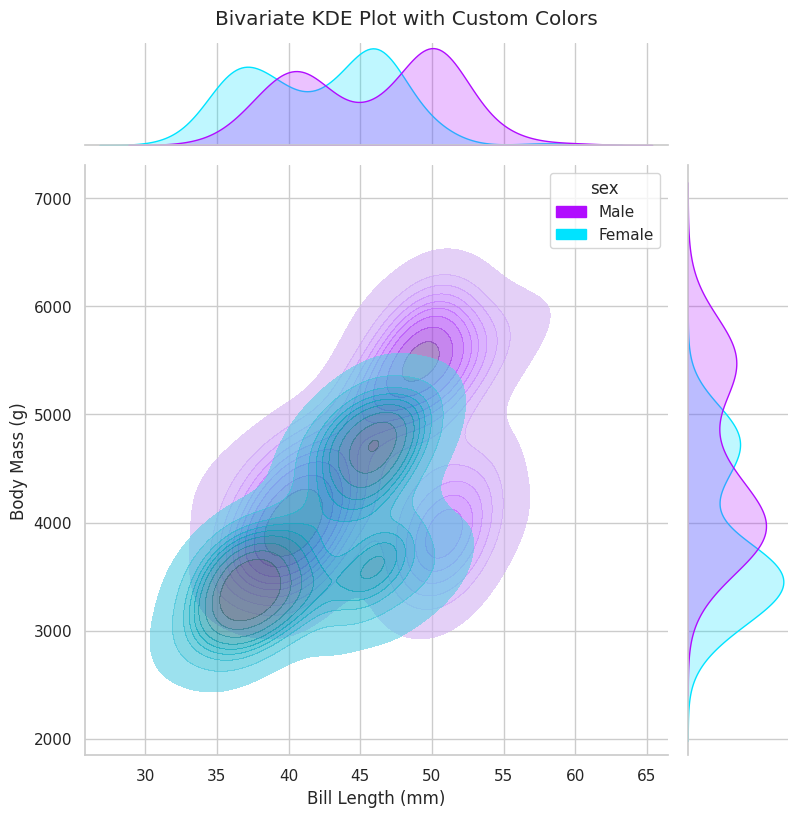

In [82]:
custom_palette = ["#b10cff", "#00e3ff"]
g = sns.jointplot(data=df, x="bill_length_mm", y="body_mass_g", hue="sex", kind="kde", fill=True, common_norm=False, alpha=0.6, height=8, palette=custom_palette)
g.set_axis_labels("Bill Length (mm)", "Body Mass (g)")
g.fig.suptitle("Bivariate KDE Plot with Custom Colors", y=1.02)
plt.show()

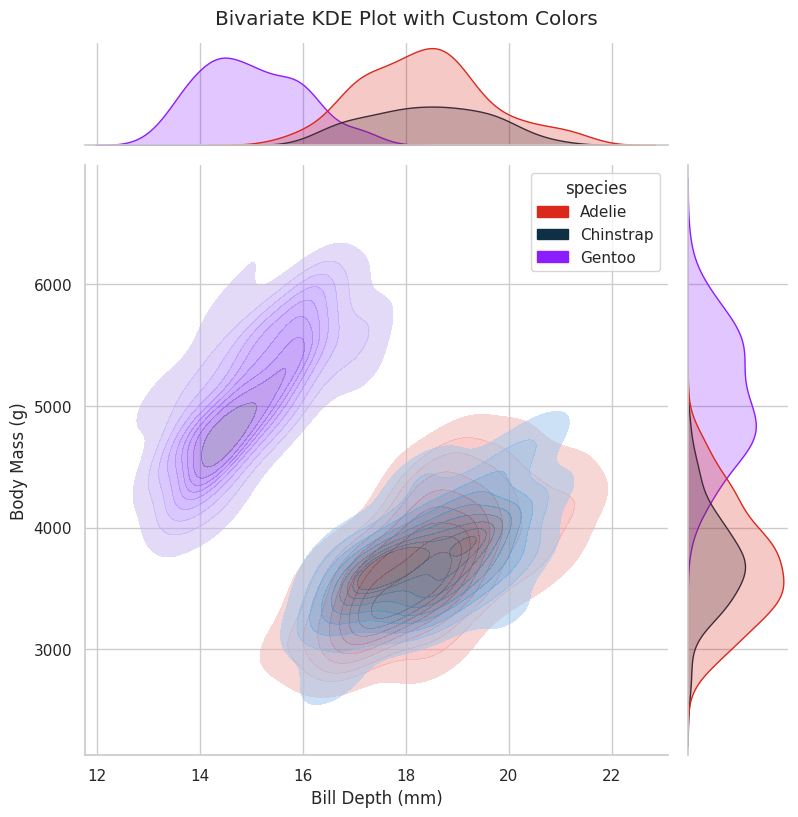

In [75]:
custom_palette = ["#db281c", "#0e2f44", "#8b1dff"]
g = sns.jointplot(data=df, x="bill_depth_mm", y="body_mass_g", hue="species", kind="kde", fill=True, common_norm=False, alpha=0.5, height=8, palette=custom_palette)
g.set_axis_labels("Bill Depth (mm)", "Body Mass (g)")
g.fig.suptitle("Bivariate KDE Plot with Custom Colors", y=1.02)
plt.show()

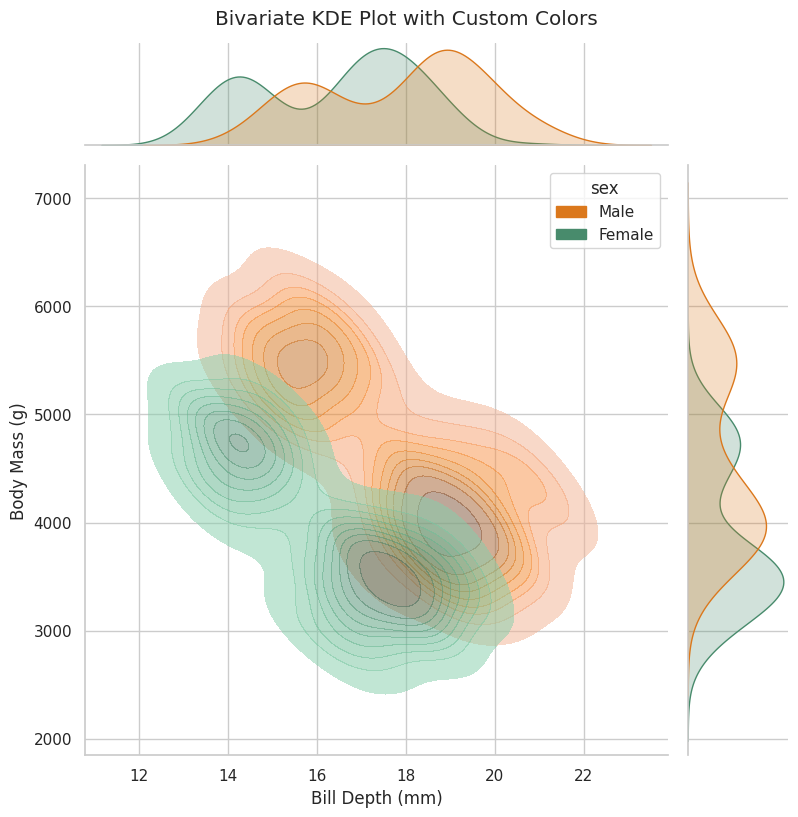

In [88]:
custom_palette = ["#db781c", "#488b6c"]
g = sns.jointplot(data=df, x="bill_depth_mm", y="body_mass_g", hue="sex", kind="kde", fill=True, common_norm=False, alpha=0.5, height=8, palette=custom_palette)
g.set_axis_labels("Bill Depth (mm)", "Body Mass (g)")
g.fig.suptitle("Bivariate KDE Plot with Custom Colors", y=1.02)
plt.show()

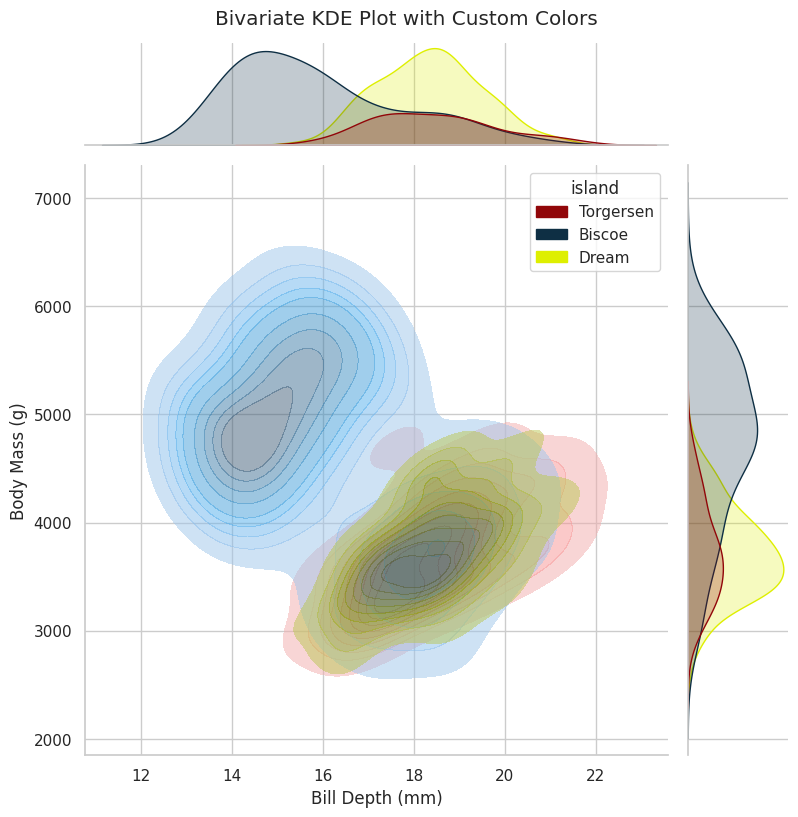

In [77]:
custom_palette = ["#910609", "#0e2f44", "#deef00"]
g = sns.jointplot(data=df, x="bill_depth_mm", y="body_mass_g", hue="island", kind="kde", fill=True, common_norm=False, alpha=0.5, height=8, palette=custom_palette)
g.set_axis_labels("Bill Depth (mm)", "Body Mass (g)")
g.fig.suptitle("Bivariate KDE Plot with Custom Colors", y=1.02)
plt.show()

In [91]:
cols = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

cv = (df[cols].std() / df[cols].mean()) * 100
print(cv.round(2))

bill_length_mm       12.43
bill_depth_mm        11.51
flipper_length_mm     7.00
body_mass_g          19.09
dtype: float64
